In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the cleaned Netflix dataset
file_path = "/home/richard/Netflix_Fresh/data/cleaned/netflix_cleaned.csv"
df = pd.read_csv(file_path)

print("NETFLIX BUSINESS INSIGHTS REPORT")
print("=" * 40)

print("\nDataset dimensions:")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSample records:")
display(df.head())

NETFLIX BUSINESS INSIGHTS REPORT

Dataset dimensions:
Rows: 8,787
Columns: 10

Column names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Data types:
show_id         object
type            object
title           object
director        object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
dtype: object

Missing values per column:
show_id            0
type               0
title              0
director        2587
country          287
date_added         0
release_year       0
rating             0
duration           0
listed_in          0
dtype: int64

Duplicate rows: 0

Sample records:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [2]:
# Overall content composition
total_titles = len(df)

type_counts = df["type"].value_counts()
type_percentages = (type_counts / total_titles * 100).round(2)

print("OVERALL CONTENT COMPOSITION")
print("=" * 40)
print("Total titles:", f"{total_titles:,}")

print("\nTitles by content type:")
for content_type, count in type_counts.items():
    print(
        f"{content_type}: {count:,} "
        f"({type_percentages[content_type]}%)"
    )

print("\nUnique release years:", df["release_year"].nunique())
print(
    "Release-year range:",
    f"{df['release_year'].min()}–{df['release_year'].max()}"
)

print("\nUnique content ratings:", df["rating"].nunique())

print(
    "Titles with missing directors:",
    f"{df['director'].isna().sum():,}"
)
print(
    "Titles with missing countries:",
    f"{df['country'].isna().sum():,}"
)

OVERALL CONTENT COMPOSITION
Total titles: 8,787

Titles by content type:
Movie: 6,124 (69.69%)
TV Show: 2,663 (30.31%)

Unique release years: 74
Release-year range: 1925–2021

Unique content ratings: 14
Titles with missing directors: 2,587
Titles with missing countries: 287


In [3]:
# Convert date_added to datetime
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce"
)

# Extract year and month of catalog addition
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# Analyze annual additions
year_added_counts = df["year_added"].value_counts().sort_index()

print("CONTENT ADDITIONS OVER TIME")
print("=" * 40)

print("\nTitles added per year:")
print(year_added_counts.to_string())

print("\nYear with the most additions:")
print(year_added_counts.idxmax(), "-", year_added_counts.max(), "titles")

print("\nMissing dates after conversion:", df["date_added"].isna().sum())

CONTENT ADDITIONS OVER TIME

Titles added per year:
year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1647
2019    2014
2020    1879
2021    1498

Year with the most additions:
2019 - 2014 titles

Missing dates after conversion: 0


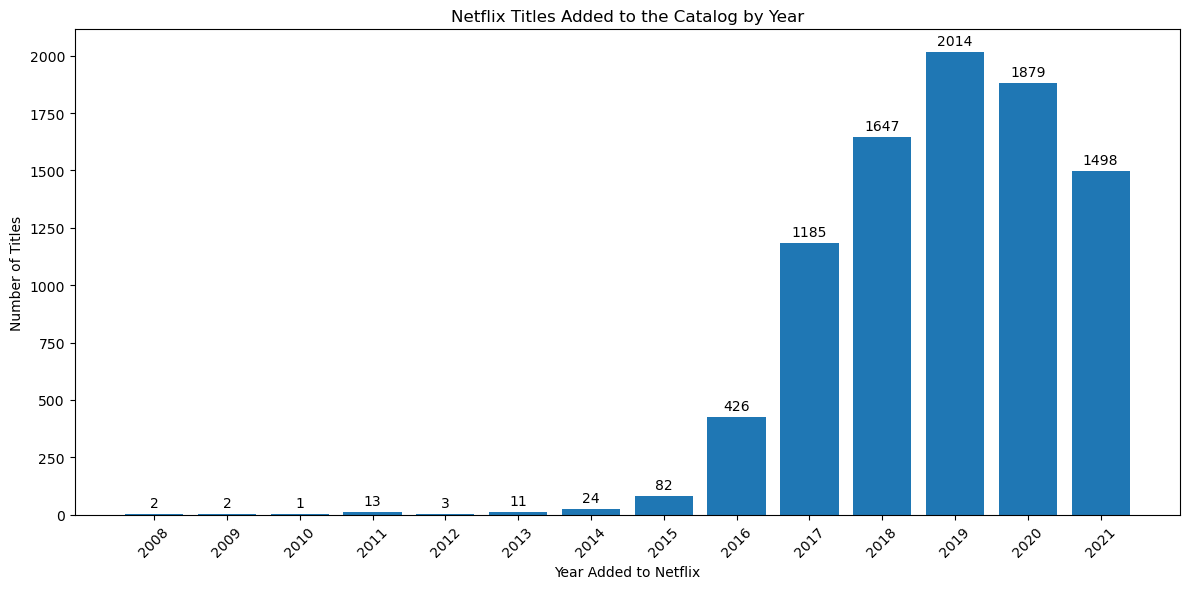

Chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/titles_added_by_year.png


In [4]:
# Create output directories
output_dir = "/home/richard/Netflix_Fresh/outputs"
figures_dir = os.path.join(output_dir, "figures")
os.makedirs(figures_dir, exist_ok=True)

# Plot annual catalog additions
plt.figure(figsize=(12, 6))

bars = plt.bar(
    year_added_counts.index.astype(str),
    year_added_counts.values
)

plt.title("Netflix Titles Added to the Catalog by Year")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()

chart_path = os.path.join(
    figures_dir,
    "titles_added_by_year.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("File location:", chart_path)

In [5]:
# Calculate the gap between original release year and catalog addition year
df["years_to_add"] = df["year_added"] - df["release_year"]

print("CONTENT AGE ANALYSIS")
print("=" * 40)

print("\nAverage years between release and catalog addition:")
print(round(df["years_to_add"].mean(), 2))

print("\nMedian years between release and catalog addition:")
print(round(df["years_to_add"].median(), 2))

print("\nTitles added in their release year:")
same_year = (df["years_to_add"] == 0).sum()
print(f"{same_year:,} ({same_year / len(df) * 100:.2f}%)")

print("\nTitles added 5 or more years after release:")
older_titles = (df["years_to_add"] >= 5).sum()
print(f"{older_titles:,} ({older_titles / len(df) * 100:.2f}%)")

print("\nTitles with negative year gaps:", (df["years_to_add"] < 0).sum())

CONTENT AGE ANALYSIS

Average years between release and catalog addition:
4.69

Median years between release and catalog addition:
1.0

Titles added in their release year:
3,237 (36.84%)

Titles added 5 or more years after release:
2,384 (27.13%)

Titles with negative year gaps: 14


In [6]:
# Content type by release year
type_year_counts = (
    df.groupby(["release_year", "type"])
    .size()
    .unstack(fill_value=0)
)

print("CONTENT TYPE BY RELEASE YEAR")
print("=" * 40)

print("\nTop 10 release years for Movies:")
print(
    df[df["type"] == "Movie"]["release_year"]
    .value_counts()
    .head(10)
    .to_string()
)

print("\nTop 10 release years for TV Shows:")
print(
    df[df["type"] == "TV Show"]["release_year"]
    .value_counts()
    .head(10)
)

print("\nYearly type table (most recent 10 release years):")
display(type_year_counts.tail(10))

CONTENT TYPE BY RELEASE YEAR

Top 10 release years for Movies:
release_year
2018    766
2017    765
2016    658
2019    632
2020    517
2015    396
2021    277
2014    264
2013    225
2012    173

Top 10 release years for TV Shows:
release_year
2020    436
2019    397
2018    378
2021    315
2017    265
2016    243
2015    159
2014     88
2012     63
2013     61
Name: count, dtype: int64

Yearly type table (most recent 10 release years):


type,Movie,TV Show
release_year,,
2012,173,63
2013,225,61
2014,264,88
2015,396,159
2016,658,243
2017,765,265
2018,766,378
2019,632,397
2020,517,436


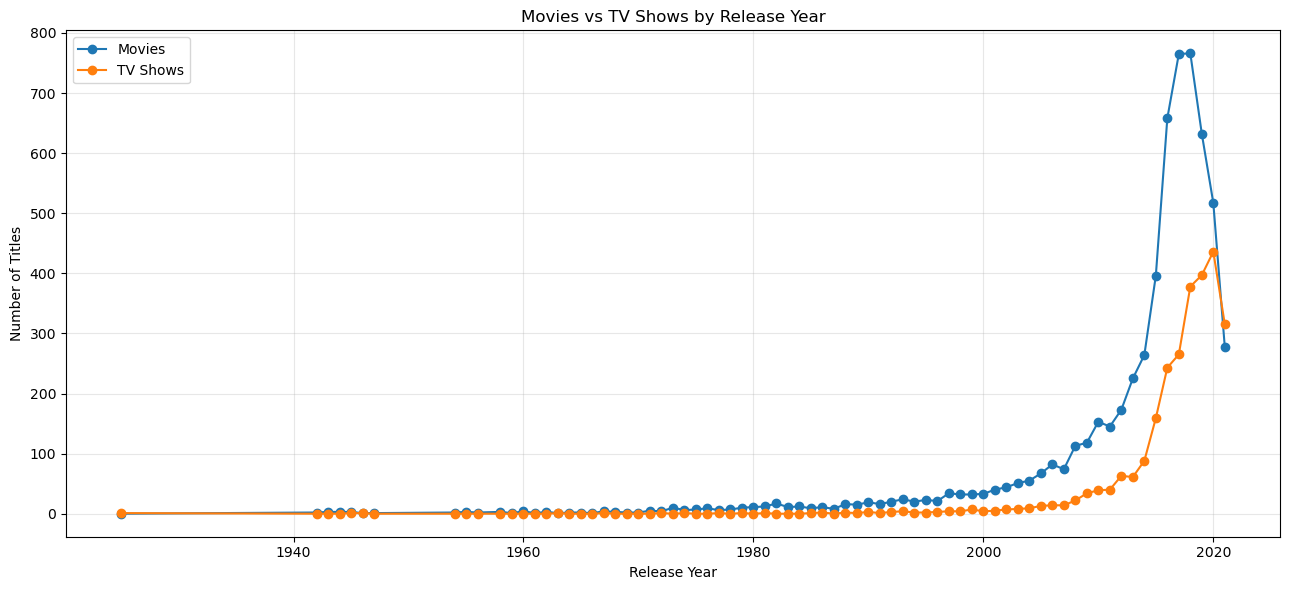

Chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/movies_vs_tv_shows_by_release_year.png


In [7]:
# Plot Movies and TV Shows by release year
plt.figure(figsize=(13, 6))

plt.plot(
    type_year_counts.index,
    type_year_counts["Movie"],
    marker="o",
    label="Movies"
)

plt.plot(
    type_year_counts.index,
    type_year_counts["TV Show"],
    marker="o",
    label="TV Shows"
)

plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

chart_path = os.path.join(
    figures_dir,
    "movies_vs_tv_shows_by_release_year.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("File location:", chart_path)

In [8]:
# Analyze monthly catalog additions
month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly_counts = (
    df["month_added"]
    .value_counts()
    .sort_index()
)

monthly_counts.index = monthly_counts.index.map(month_names)

print("MONTHLY CATALOG ADDITIONS")
print("=" * 40)

print("\nTitles added by month:")
print(monthly_counts.to_string())

print("\nMonth with the most additions:")
print(monthly_counts.idxmax(), "-", monthly_counts.max(), "titles")

print("\nMonth with the fewest additions:")
print(monthly_counts.idxmin(), "-", monthly_counts.min(), "titles")

MONTHLY CATALOG ADDITIONS

Titles added by month:
month_added
January      737
February     562
March        739
April        763
May          632
June         728
July         827
August       754
September    769
October      759
November     705
December     812

Month with the most additions:
July - 827 titles

Month with the fewest additions:
February - 562 titles


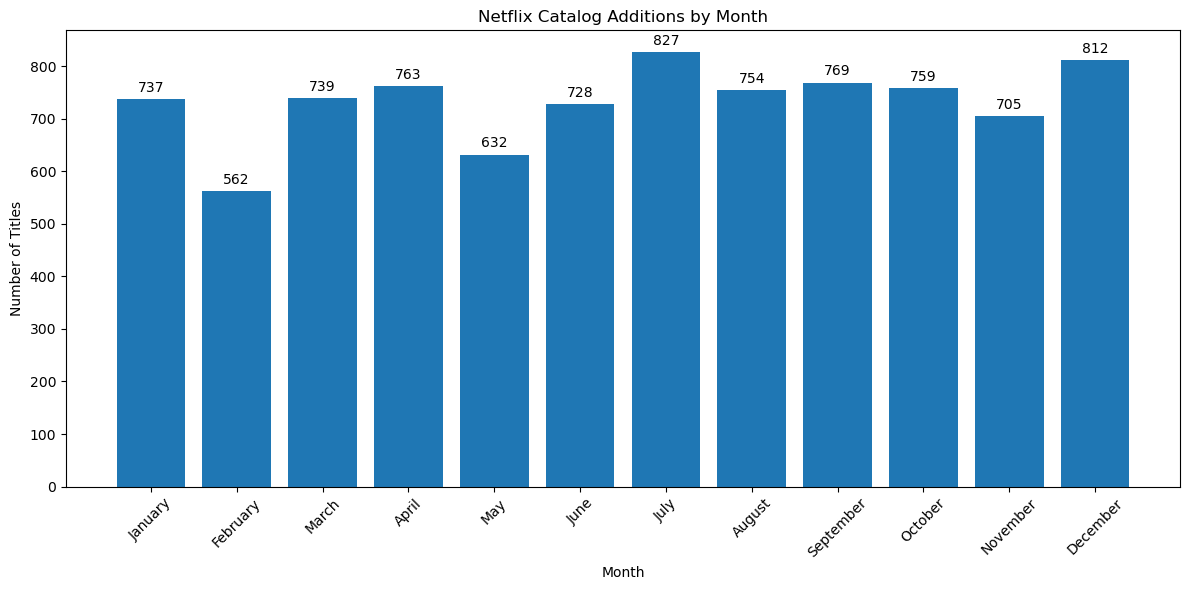

Chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/monthly_catalog_additions.png


In [9]:
# Visualize monthly Netflix catalog additions
plt.figure(figsize=(12, 6))

bars = plt.bar(monthly_counts.index, monthly_counts.values)

plt.title("Netflix Catalog Additions by Month")
plt.xlabel("Month")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.bar_label(bars, fmt="%d", padding=3)
plt.tight_layout()

chart_path = os.path.join(
    figures_dir,
    "monthly_catalog_additions.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("File location:", chart_path)

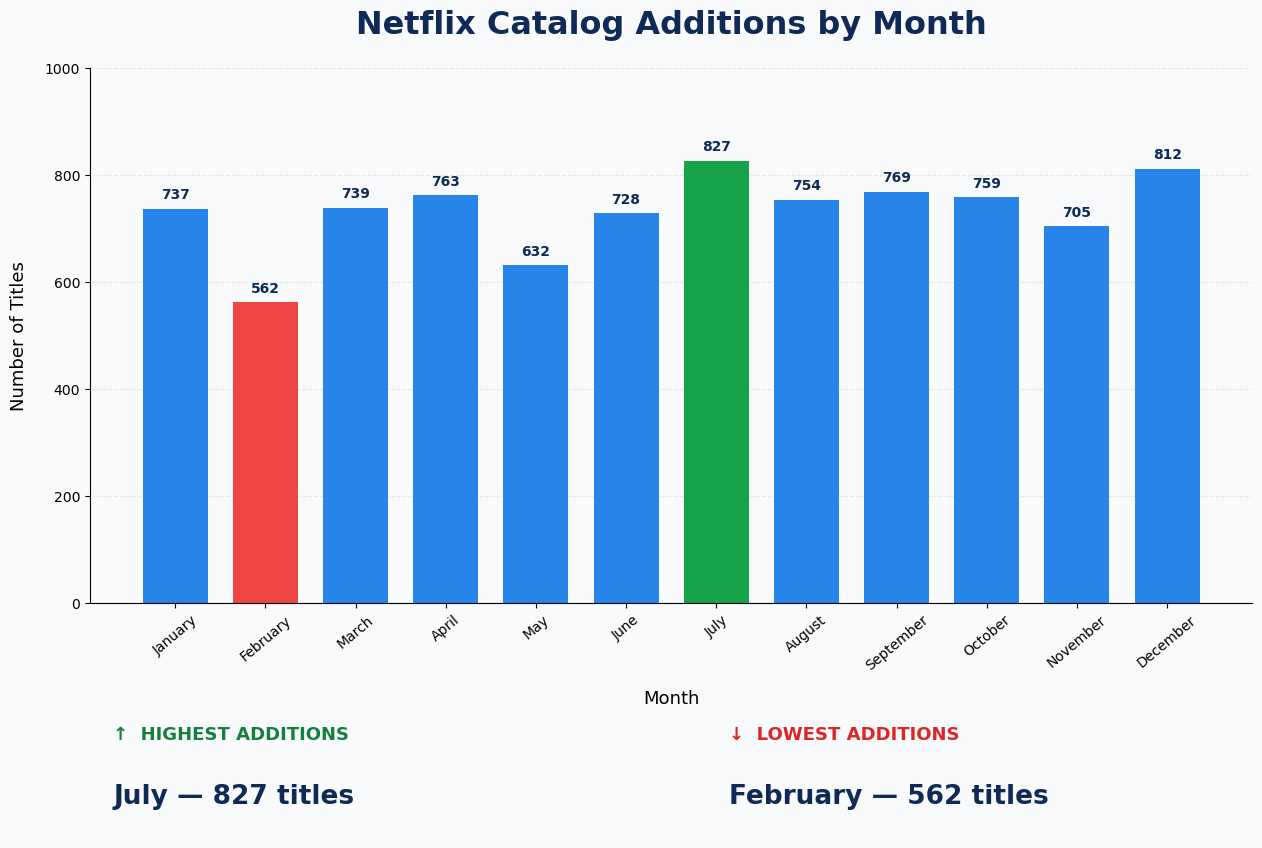

Infographic generated successfully!
Saved to: /home/richard/Netflix_Fresh/outputs/figures/netflix_monthly_additions_infographic.png


In [10]:

import matplotlib.pyplot as plt
import numpy as np
import os

# Output location
output_path = "/home/richard/Netflix_Fresh/outputs/figures"
os.makedirs(output_path, exist_ok=True)

# Monthly Netflix catalog additions
months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

counts = [737, 562, 739, 763, 632, 728, 827, 754, 769, 759, 705, 812]

# Identify highest and lowest months
max_idx = np.argmax(counts)
min_idx = np.argmin(counts)

# Create infographic layout
fig = plt.figure(figsize=(15, 10), facecolor="#F8FAFC")
gs = fig.add_gridspec(2, 1, height_ratios=[3.8, 1], hspace=0.28)

# Main bar chart
ax = fig.add_subplot(gs[0])
ax.set_facecolor("#F8FAFC")

colors = [
    "#2784E8" if i != max_idx and i != min_idx
    else "#16A34A" if i == max_idx
    else "#EF4444"
    for i in range(len(counts))
]

bars = ax.bar(months, counts, color=colors, width=0.72)

ax.set_title(
    "Netflix Catalog Additions by Month",
    fontsize=23, fontweight="bold", color="#102A56", pad=25
)
ax.set_xlabel("Month", fontsize=13, labelpad=12)
ax.set_ylabel("Number of Titles", fontsize=13, labelpad=12)
ax.set_ylim(0, 1000)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=40, labelsize=10)
ax.tick_params(axis="y", labelsize=10)

ax.bar_label(bars, labels=[str(n) for n in counts], padding=5,
             fontsize=10, fontweight="bold", color="#102A56")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Summary panels
summary = fig.add_subplot(gs[1])
summary.axis("off")

summary.text(
    0.02, 0.70, "↑  HIGHEST ADDITIONS",
    fontsize=13, fontweight="bold", color="#15803D",
    transform=summary.transAxes
)
summary.text(
    0.02, 0.25, f"{months[max_idx]} — {counts[max_idx]:,} titles",
    fontsize=19, fontweight="bold", color="#102A56",
    transform=summary.transAxes
)

summary.text(
    0.55, 0.70, "↓  LOWEST ADDITIONS",
    fontsize=13, fontweight="bold", color="#DC2626",
    transform=summary.transAxes
)
summary.text(
    0.55, 0.25, f"{months[min_idx]} — {counts[min_idx]:,} titles",
    fontsize=19, fontweight="bold", color="#102A56",
    transform=summary.transAxes
)

# Save the infographic
file_path = os.path.join(
    output_path, "netflix_monthly_additions_infographic.png"
)

plt.savefig(
    file_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)
plt.show()

print("Infographic generated successfully!")
print("Saved to:", file_path)


In [11]:
# Analyze annual catalog additions by content type
annual_type_additions = (
    df.dropna(subset=["year_added"])
    .groupby(["year_added", "type"])
    .size()
    .unstack(fill_value=0)
)

print("ANNUAL CATALOG ADDITIONS BY CONTENT TYPE")
print("=" * 45)

display(annual_type_additions)

print("\nYear with the most Movie additions:")
print(annual_type_additions["Movie"].idxmax(),
      "-", annual_type_additions["Movie"].max(), "Movies")

print("\nYear with the most TV Show additions:")
print(annual_type_additions["TV Show"].idxmax(),
      "-", annual_type_additions["TV Show"].max(), "TV Shows")

ANNUAL CATALOG ADDITIONS BY CONTENT TYPE


type,Movie,TV Show
year_added,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,5
2015,56,26
2016,251,175



Year with the most Movie additions:
2019 - 1423 Movies

Year with the most TV Show additions:
2020 - 595 TV Shows


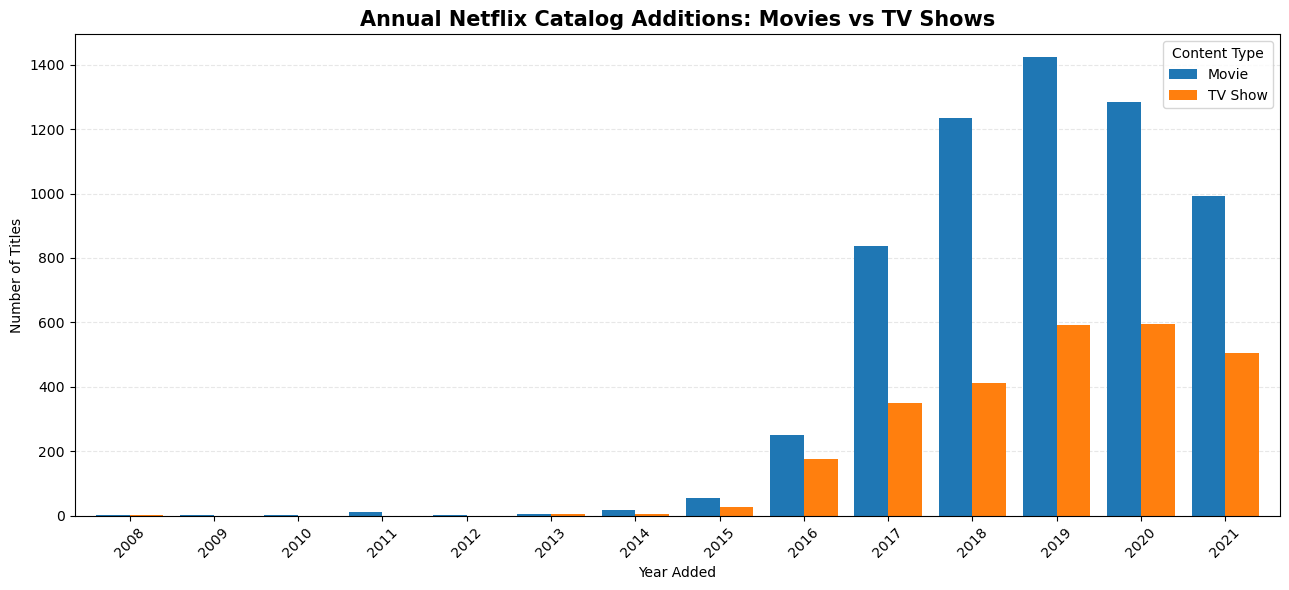

Chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/annual_additions_by_content_type.png


In [12]:
# Plot annual catalog additions by content type
ax = annual_type_additions.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title(
    "Annual Netflix Catalog Additions: Movies vs TV Shows",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Year Added")
ax.set_ylabel("Number of Titles")
ax.legend(title="Content Type")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

chart_path = os.path.join(
    figures_dir,
    "annual_additions_by_content_type.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("File location:", chart_path)

In [13]:
# Content ratings by content type
rating_type_counts = pd.crosstab(
    df["rating"],
    df["type"]
)

print("CONTENT RATINGS BY CONTENT TYPE")
print("=" * 40)

display(rating_type_counts)

print("\nTop 5 Movie ratings:")
print(
    df[df["type"] == "Movie"]["rating"]
    .value_counts()
    .head(5)
    .to_string()
)

print("\nTop 5 TV Show ratings:")
print(
    df[df["type"] == "TV Show"]["rating"]
    .value_counts()
    .head(5)
    .to_string()
)

CONTENT RATINGS BY CONTENT TYPE


type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,796,2
TV-14,1426,729
TV-G,126,94
TV-MA,2062,1143



Top 5 Movie ratings:
rating
TV-MA    2062
TV-14    1426
R         796
TV-PG     540
PG-13     490

Top 5 TV Show ratings:
rating
TV-MA    1143
TV-14     729
TV-PG     321
TV-Y7     194
TV-Y      175


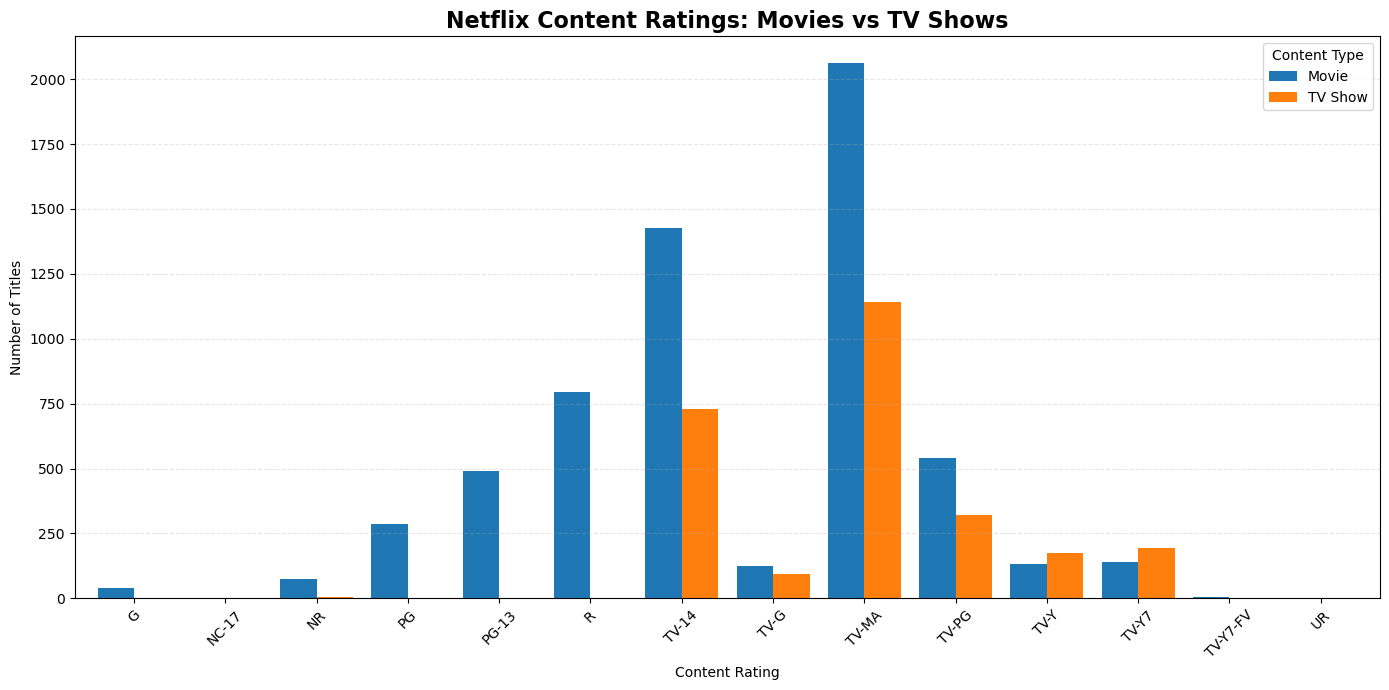

Chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/ratings_by_content_type.png


In [14]:
# Plot ratings by content type
rating_type_counts.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title(
    "Netflix Content Ratings: Movies vs TV Shows",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

chart_path = os.path.join(
    figures_dir,
    "ratings_by_content_type.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("File location:", chart_path)

In [15]:
# Analyze duration by content type
print("CONTENT DURATION ANALYSIS")
print("=" * 40)

print("\nMost common Movie durations:")
print(
    df[df["type"] == "Movie"]["duration"]
    .value_counts()
    .head(10)
    .to_string()
)

print("\nMost common TV Show durations:")
print(
    df[df["type"] == "TV Show"]["duration"]
    .value_counts()
    .head(10)
    .to_string()
)

# Extract numeric duration values
df["duration_value"] = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Summarize typical duration values
movie_durations = df.loc[
    df["type"] == "Movie", "duration_value"
].dropna()

tv_durations = df.loc[
    df["type"] == "TV Show", "duration_value"
].dropna()

print("\nMovie runtime in minutes:")
print("Median:", movie_durations.median())
print("Mean:", round(movie_durations.mean(), 2))

print("\nTV Show seasons:")
print("Median:", tv_durations.median())
print("Mean:", round(tv_durations.mean(), 2))

CONTENT DURATION ANALYSIS

Most common Movie durations:
duration
90 min     152
93 min     146
94 min     146
97 min     146
91 min     144
95 min     137
96 min     130
92 min     129
102 min    122
98 min     120

Most common TV Show durations:
duration
1 Season      1790
2 Seasons      421
3 Seasons      198
4 Seasons       94
5 Seasons       64
6 Seasons       33
7 Seasons       23
8 Seasons       17
9 Seasons        9
10 Seasons       6

Movie runtime in minutes:
Median: 98.0
Mean: 99.57

TV Show seasons:
Median: 1.0
Mean: 1.75


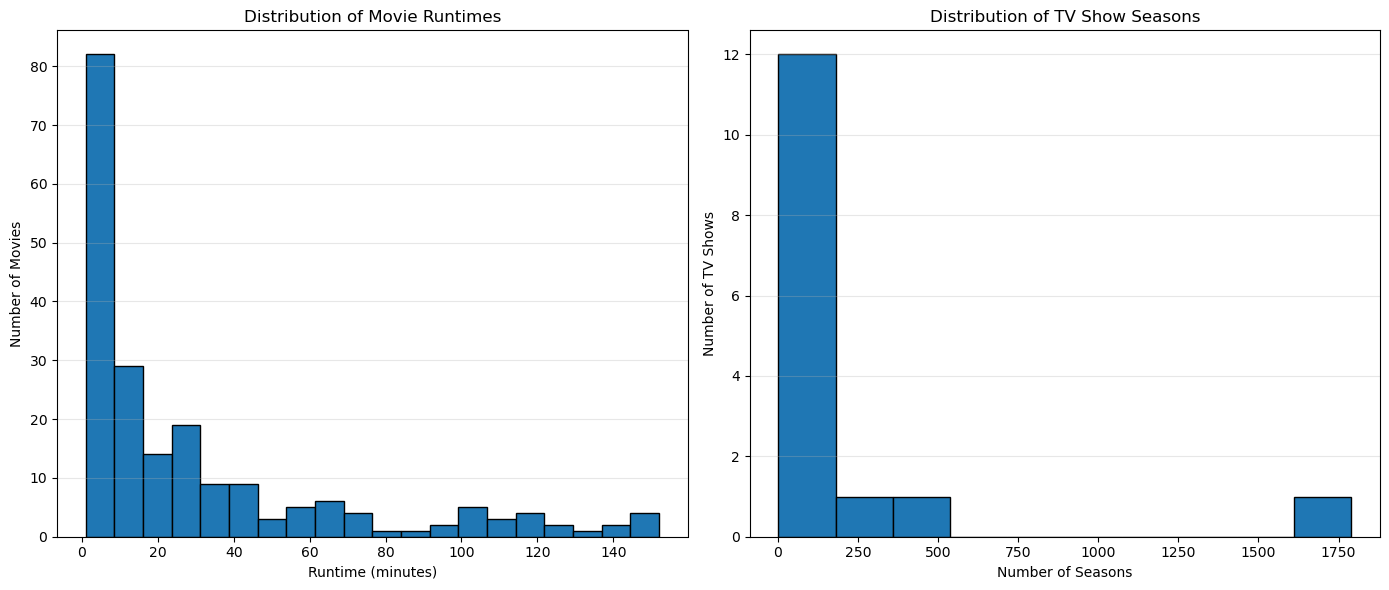

Chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/content_duration_distributions.png


In [16]:
# Create side-by-side duration charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Movie runtime distribution
movie_durations.value_counts().sort_index().plot(
    kind="hist",
    bins=20,
    ax=axes[0],
    edgecolor="black"
)

axes[0].set_title("Distribution of Movie Runtimes")
axes[0].set_xlabel("Runtime (minutes)")
axes[0].set_ylabel("Number of Movies")
axes[0].grid(axis="y", alpha=0.3)

# TV Show season distribution
tv_durations.value_counts().sort_index().plot(
    kind="hist",
    bins=10,
    ax=axes[1],
    edgecolor="black"
)

axes[1].set_title("Distribution of TV Show Seasons")
axes[1].set_xlabel("Number of Seasons")
axes[1].set_ylabel("Number of TV Shows")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()

chart_path = os.path.join(
    figures_dir,
    "content_duration_distributions.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("File location:", chart_path)

In [17]:
# Consolidated catalog growth and content age analysis

print("NETFLIX CATALOG GROWTH SUMMARY")
print("=" * 45)

print("\n1. Catalog additions")
print("First year in dataset:", int(df["year_added"].min()))
print("Last year in dataset:", int(df["year_added"].max()))
print("Peak addition year:", int(year_added_counts.idxmax()))
print("Titles added in peak year:", int(year_added_counts.max()))

print("\n2. Content age at catalog addition")
valid_gaps = df["years_to_add"].dropna()

print("Average release-to-addition gap:",
      round(valid_gaps.mean(), 2), "years")
print("Median release-to-addition gap:",
      round(valid_gaps.median(), 2), "years")
print("Added in release year:",
      int((valid_gaps == 0).sum()))
print("Added 5+ years after release:",
      int((valid_gaps >= 5).sum()))
print("Negative year gaps:",
      int((valid_gaps < 0).sum()))

print("\n3. Content added by type")
print(
    df.groupby("type")["show_id"]
    .count()
    .sort_values(ascending=False)
    .to_string()
)

NETFLIX CATALOG GROWTH SUMMARY

1. Catalog additions
First year in dataset: 2008
Last year in dataset: 2021
Peak addition year: 2019
Titles added in peak year: 2014

2. Content age at catalog addition
Average release-to-addition gap: 4.69 years
Median release-to-addition gap: 1.0 years
Added in release year: 3237
Added 5+ years after release: 2384
Negative year gaps: 14

3. Content added by type
type
Movie      6124
TV Show    2663


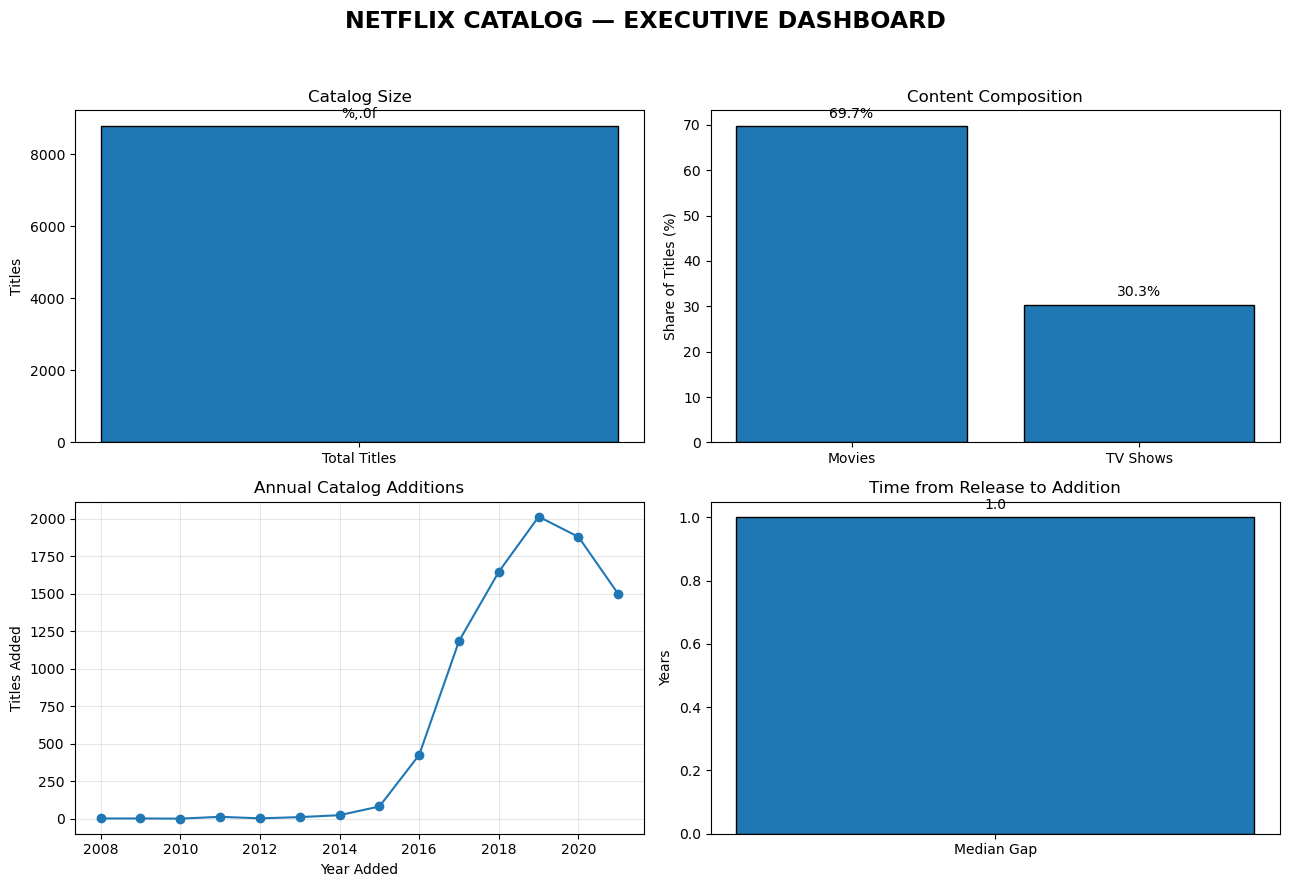

Executive dashboard saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/netflix_executive_dashboard.png


In [18]:
# Executive KPI dashboard
from matplotlib.ticker import FuncFormatter

total_titles = len(df)
movie_count = (df["type"] == "Movie").sum()
tv_count = (df["type"] == "TV Show").sum()
movie_percentage = movie_count / total_titles * 100
tv_percentage = tv_count / total_titles * 100

peak_year = int(year_added_counts.idxmax())
peak_additions = int(year_added_counts.max())
median_gap = df["years_to_add"].median()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle(
    "NETFLIX CATALOG — EXECUTIVE DASHBOARD",
    fontsize=17,
    fontweight="bold"
)

# KPI 1: Total titles
axes[0, 0].bar(
    ["Total Titles"], [total_titles],
    edgecolor="black"
)
axes[0, 0].set_title("Catalog Size")
axes[0, 0].set_ylabel("Titles")
axes[0, 0].bar_label(
    axes[0, 0].containers[0],
    fmt="%,.0f",
    padding=4
)

# KPI 2: Content composition
axes[0, 1].bar(
    ["Movies", "TV Shows"],
    [movie_percentage, tv_percentage],
    edgecolor="black"
)
axes[0, 1].set_title("Content Composition")
axes[0, 1].set_ylabel("Share of Titles (%)")
axes[0, 1].bar_label(
    axes[0, 1].containers[0],
    fmt="%.1f%%",
    padding=4
)

# KPI 3: Annual additions
axes[1, 0].plot(
    year_added_counts.index,
    year_added_counts.values,
    marker="o"
)
axes[1, 0].set_title("Annual Catalog Additions")
axes[1, 0].set_xlabel("Year Added")
axes[1, 0].set_ylabel("Titles Added")
axes[1, 0].grid(alpha=0.3)

# KPI 4: Release-to-addition gap
axes[1, 1].bar(
    ["Median Gap"],
    [median_gap],
    edgecolor="black"
)
axes[1, 1].set_title("Time from Release to Addition")
axes[1, 1].set_ylabel("Years")
axes[1, 1].bar_label(
    axes[1, 1].containers[0],
    fmt="%.1f",
    padding=4
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

dashboard_path = os.path.join(
    figures_dir,
    "netflix_executive_dashboard.png"
)

plt.savefig(dashboard_path, dpi=300, bbox_inches="tight")
plt.show()

print("Executive dashboard saved successfully!")
print("File location:", dashboard_path)

In [19]:
# Generate key business insights from the dataset

print("NETFLIX BUSINESS INSIGHTS")
print("=" * 50)

# 1. Content composition
content_share = df["type"].value_counts(normalize=True) * 100

print("\n1. CONTENT COMPOSITION")
print(
    f"Movies represent {content_share['Movie']:.2f}% "
    f"of the catalog."
)
print(
    f"TV Shows represent {content_share['TV Show']:.2f}% "
    f"of the catalog."
)

# 2. Catalog growth
print("\n2. CATALOG GROWTH")
print(
    f"The highest number of catalog additions occurred in "
    f"{int(year_added_counts.idxmax())}, with "
    f"{int(year_added_counts.max()):,} titles."
)

# 3. Content age
valid_gaps = df["years_to_add"].dropna()

print("\n3. CONTENT AGE")
print(
    f"The median release-to-addition gap is "
    f"{valid_gaps.median():.1f} year(s)."
)
print(
    f"{(valid_gaps >= 5).sum():,} titles were added "
    f"at least five years after release."
)

# 4. Ratings
top_rating = df["rating"].value_counts().idxmax()
top_rating_count = df["rating"].value_counts().max()

print("\n4. CONTENT RATINGS")
print(
    f"The most common rating is {top_rating}, "
    f"covering {top_rating_count:,} titles."
)

# 5. Genres
genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

print("\n5. GENRE DISTRIBUTION")
print(
    f"The most common genre category is "
    f"{genre_counts.index[0]}, with "
    f"{genre_counts.iloc[0]:,} title-genre entries."
)

# 6. Data quality
print("\n6. DATA QUALITY")
print(
    f"Titles with missing director information: "
    f"{df['director'].isna().sum():,}"
)
print(
    f"Titles with missing country information: "
    f"{df['country'].isna().sum():,}"
)
print(
    f"Negative release-to-addition gaps: "
    f"{(valid_gaps < 0).sum():,}"
)

NETFLIX BUSINESS INSIGHTS

1. CONTENT COMPOSITION
Movies represent 69.69% of the catalog.
TV Shows represent 30.31% of the catalog.

2. CATALOG GROWTH
The highest number of catalog additions occurred in 2019, with 2,014 titles.

3. CONTENT AGE
The median release-to-addition gap is 1.0 year(s).
2,384 titles were added at least five years after release.

4. CONTENT RATINGS
The most common rating is TV-MA, covering 3,205 titles.

5. GENRE DISTRIBUTION
The most common genre category is International Movies, with 2,752 title-genre entries.

6. DATA QUALITY
Titles with missing director information: 2,587
Titles with missing country information: 287
Negative release-to-addition gaps: 14


## 7. Business Insights and Recommendations

### 7.1 Key Business Insights

**1. Movie-dominated catalog**

Movies account for 69.69% of the 8,787 titles, while TV Shows represent 30.31%. This indicates that movies form the larger share of the catalog in the dataset.

**2. Catalog additions peaked in 2019**

The dataset records 2,014 catalog additions in 2019, the highest annual total in the observed period of 2008–2021. Additions declined in 2020 and 2021, although the available data alone cannot establish the reasons for this change.

**3. A substantial share of older content**

The median time between a title's release year and its catalog addition year is one year. However, 2,384 titles were added at least five years after their original release, demonstrating that the catalog also includes older content.

**4. Mature-rated content is common**

TV-MA is the most frequent rating, appearing on 3,205 titles. This describes the catalog's rating distribution but does not establish which content audiences watch most.

**5. International content is prominent**

International Movies is the most frequent genre/category label, with 2,752 title-category entries. This suggests that international content is a significant component of the dataset's catalog classification.

**6. Metadata completeness can be improved**

Director information is missing for 2,587 titles, while country information is missing for 287 titles. These gaps may limit some geographic and creator-level analyses.

### 7.2 Actionable Recommendations

1. **Review content portfolio balance.** Monitor the movie-to-TV-show mix alongside acquisition costs, audience engagement, and performance data before making content investment decisions.

2. **Investigate catalog addition patterns.** Examine the factors associated with the 2019 peak and subsequent decline using complete acquisition records and data beyond 2021.

3. **Evaluate older titles separately.** Analyze viewing hours, completion rates, licensing costs, and retention metrics for older titles to assess their continuing business value.

4. **Strengthen metadata quality.** Prioritize completing missing director and country fields and validate release dates against reliable sources.

5. **Explore international catalog coverage.** Compare content availability across countries and language categories, and combine these findings with regional viewing data before recommending expansion.

6. **Use ratings for appropriate classification.** Review rating distributions when assessing catalog suitability for different audience segments, while relying on actual audience research to determine demand.

### 7.3 Analytical Limitations

This analysis uses a catalog dataset containing 8,787 titles and covers observed catalog additions from 2008 to 2021. It does not include viewing hours, subscriber behavior, revenue, acquisition costs, or profitability. Consequently, the findings describe catalog composition and historical addition patterns rather than audience preferences or financial performance.

The 14 negative release-to-addition year gaps should be reviewed for possible date inconsistencies. Genre totals represent title-category associations, because one title can have multiple categories.


# Netflix Business Intelligence Report

## Executive Summary

This project analyzes Netflix's catalog using Python and pandas to identify content composition, catalog addition trends, release-to-addition gaps, ratings, genre categories, and metadata quality.

The cleaned dataset contains **8,787 titles and 10 columns**, covering content with release years from 1925 to 2021 and catalog additions from 2008 to 2021.

Movies account for **69.69%** of the catalog, compared with **30.31%** for TV Shows. Catalog additions peaked in **2019, with 2,014 titles**. The median gap between a title's release year and its catalog addition year is **one year**, while 2,384 titles were added at least five years after release.

TV-MA is the most common content rating, appearing on 3,205 titles. International Movies is the most frequent genre/category label, with 2,752 title-category entries.

The analysis also identified incomplete metadata, including 2,587 missing director values and 287 missing country values. Fourteen titles have negative release-to-addition year gaps and require further review.

## Conclusion

The analysis demonstrates how exploratory data analysis and visualization can transform a catalog dataset into useful business intelligence. The findings describe Netflix's historical catalog composition and addition patterns, while highlighting opportunities to improve metadata quality and investigate content portfolio trends.

Further analysis incorporating viewing hours, subscriber engagement, licensing costs, revenue, and country-specific demand would be required to assess content performance and support investment decisions.
